# F1 Race Intelligence — Exploratory Analysis & Verification
### Master's Degree in Data Science | University of Milan (UNIMI)
**Course:** Coding for Data Science and Data Management — Python Module  
**Project:** Box, Box — Formula 1 Race Analytics

This notebook demonstrates the end-to-end analytical pipeline on real Formula 1 timing and tyre data (cached from the **Jolpica F1 API** and **OpenF1 API**). All computations and charts are imported from the modular package under `src/f1_analysis/`.

## 1. Environment & Package Imports

In [1]:
import os
import sys
import tempfile
from pathlib import Path

# Ensure writable Matplotlib cache dir and add src/ to sys.path
os.environ.setdefault("MPLCONFIGDIR", tempfile.gettempdir())
root_dir = Path.cwd() if (Path.cwd() / "src").exists() else Path.cwd().parent
src_dir = root_dir / "src"
if str(src_dir) not in sys.path:
    sys.path.insert(0, str(src_dir))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from f1_analysis.analysis.driver_performance import (
    compare_teammates,
    compute_driver_pace_metrics,
)
from f1_analysis.analysis.pitstop_analysis import (
    analyze_undercut,
    compute_pit_stop_summary,
    strategy_vs_result,
)
from f1_analysis.analysis.race_dynamics import (
    compute_gap_to_leader,
    compute_net_position_changes,
    compute_position_progression,
)
from f1_analysis.analysis.team_performance import (
    compute_constructor_pace_ranking,
    compute_constructor_points_summary,
    compute_season_constructor_points,
)
from f1_analysis.analysis.tyre_analysis import (
    compute_compound_degradation,
    compute_driver_stint_summary,
)
from f1_analysis.data.data_loader import F1DataLoader
from f1_analysis.pipeline import build_race_dataset
from f1_analysis.visualization.charts import (
    plot_constructor_pace,
    plot_driver_pace_distributions,
    plot_pit_stop_times,
    plot_position_progression,
    plot_tyre_degradation,
)

pd.set_option("display.max_columns", 20)
pd.set_option("display.width", 120)
print("f1_analysis modules imported successfully.")

f1_analysis modules imported successfully.


## 2. Data Ingestion & Preprocessing Pipeline
We load the **2024 Bahrain Grand Prix (Round 1)** via `build_race_dataset(2024, 1)`, which:
1. Retrieves paginated race results, lap-by-lap timings (1,129 laps), and pit stops (43 stops) from Jolpica.
2. Matches the race date to OpenF1 session `9472` and joins stint/compound data using driver racing numbers.
3. Flags pit in-laps, pit out-laps, lap 1, and slow laps (>107% of each driver's median pace) without deleting records.
4. Computes fuel-corrected lap times using a linear fuel burn model ($100\text{ kg}$ start load, $0.03\text{ s/kg}$ sensitivity).

In [2]:
ds = build_race_dataset(year=2024, round_num=1)
df_results = ds.results
df_laps = ds.laps
df_pitstops = ds.pitstops

print(f"Race: {ds.info.get('season')} {ds.info.get('race_name')} ({ds.info.get('circuit')})")
print(f"Classified drivers: {len(df_results)} | Total lap rows: {len(df_laps)} | Pit stops: {len(df_pitstops)}")
print(f"Laps matched with OpenF1 tyre compound: {df_laps['compound'].notna().sum()} / {len(df_laps)}")
print("\nLap cleaning breakdown:")
print(df_laps["exclusion_reason"].fillna("representative").value_counts())

Race: 2024 Bahrain Grand Prix (Bahrain International Circuit)
Classified drivers: 20 | Total lap rows: 1129 | Pit stops: 43
Laps matched with OpenF1 tyre compound: 1129 / 1129

Lap cleaning breakdown:
exclusion_reason
representative    1024
pit_out_lap         43
pit_in_lap          42
first_lap           20
Name: count, dtype: int64


## 3. Module A — Driver Performance & Teammate Comparison
We evaluate representative race pace using both parametric (mean, sample standard deviation) and non-parametric (median, interquartile range) statistics.

In [3]:
driver_pace = compute_driver_pace_metrics(df_laps, use_fuel_corrected=True)
driver_pace.head(10)

,driver_id,total_laps,representative_laps,mean_lap_sec,median_lap_sec,std_lap_sec,iqr_lap_sec,fastest_lap_sec,gap_to_fastest_sec
0,max_verstappen,57,52,97.162501,97.325553,0.702927,0.984145,94.608000,0.000000
1,perez,57,52,97.560089,97.586500,0.627584,0.941684,96.290211,0.260947
2,sainz,57,52,97.621296,97.588605,0.555650,0.939579,96.349105,0.263053
3,norris,57,52,97.987811,97.998842,0.626767,0.915947,96.265474,0.673289
4,leclerc,57,52,97.894623,98.037395,0.653934,0.872316,95.932105,0.711842
5,russell,57,52,98.006523,98.114342,0.661102,1.020184,96.511263,0.788789
6,hamilton,57,52,98.021316,98.133921,0.595881,0.862316,96.722000,0.808368
7,piastri,57,52,98.061965,98.177500,0.606119,0.918158,96.668737,0.851947
8,hulkenberg,56,50,98.348364,98.294500,0.716091,0.687421,97.202421,0.968947
9,alonso,57,52,98.443952,98.408763,0.801469,1.139329,96.672684,1.083211


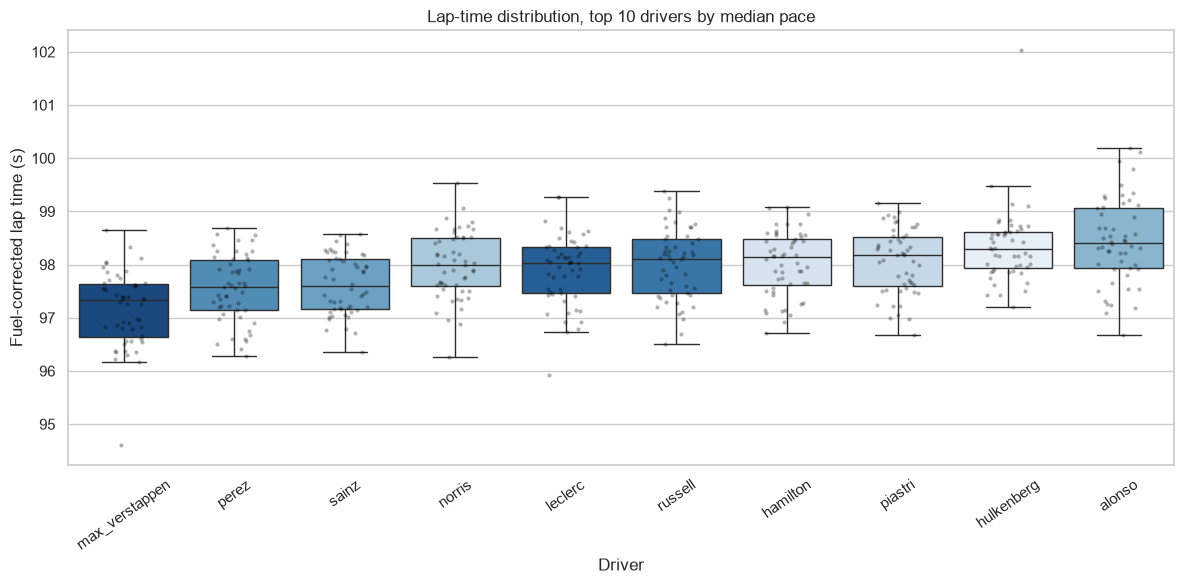

In [4]:
fig = plot_driver_pace_distributions(df_laps, top_n=10, use_fuel_corrected=True)
plt.show()

### Intra-Team (Teammate) Pace Comparison
**Statistical note:** Welch's $t$-test and the Mann-Whitney $U$ test treat laps as independent draws. Because consecutive laps within a stint are autocorrelated and teammates may run different stint lengths, $p$-values are optimistic and should be interpreted alongside the median pace delta.

In [5]:
teammates = compare_teammates(df_laps, df_results, use_fuel_corrected=True)
teammates

,constructor_id,constructor_name,driver_1,driver_2,n_laps_1,n_laps_2,driver_1_median_sec,driver_2_median_sec,delta_sec,faster_driver,welch_t_p_value,mannwhitney_p_value,significant_at_alpha
0,alpine,Alpine F1 Team,ocon,gasly,51,49,99.185000,98.750105,0.434895,gasly,0.000490,0.001329,True
1,aston_martin,Aston Martin,alonso,stroll,52,52,98.408763,98.638921,-0.230158,alonso,0.135721,0.109755,False
2,ferrari,Ferrari,sainz,leclerc,52,52,97.588605,98.037395,-0.448789,sainz,0.023724,0.023472,True
3,haas,Haas F1 Team,kevin_magnussen,hulkenberg,51,50,99.062632,98.294500,0.768132,hulkenberg,0.000062,0.000006,True
4,mclaren,McLaren,norris,piastri,52,52,97.998842,98.177500,-0.178658,norris,0.541051,0.488701,False
5,mercedes,Mercedes,russell,hamilton,52,52,98.114342,98.133921,-0.019579,russell,0.904839,0.847911,False
6,rb,RB F1 Team,ricciardo,tsunoda,51,51,98.976526,98.942263,0.034263,tsunoda,0.710681,0.668409,False
7,red_bull,Red Bull,max_verstappen,perez,52,52,97.325553,97.586500,-0.260947,max_verstappen,0.002992,0.005028,True
8,sauber,Sauber,zhou,bottas,51,51,98.957263,99.285000,-0.327737,zhou,0.053552,0.054756,False
9,williams,Williams,albon,sargeant,51,48,99.073053,98.816132,0.256921,sargeant,0.981745,0.252321,False


## 4. Module B — Tyre Degradation Modeling
Instead of pooling all drivers together (which confounds car performance with tyre choice), `compute_compound_degradation` demeans lap time and tyre age **within each driver stint** before fitting OLS:
$$y_{i} - \bar{y}_{s} = \beta \, (a_{i} - \bar{a}_{s}) + \varepsilon_{i}$$
Below we compare the estimated degradation slope ($\beta$, in seconds per lap of tyre age) **with** and **without** fuel-load correction to illustrate how car mass reduction masks tyre wear.

In [6]:
deg_fuel_corrected = compute_compound_degradation(df_laps, use_fuel_corrected=True)
deg_raw = compute_compound_degradation(df_laps, use_fuel_corrected=False)

print("=== Fuel-Corrected Within-Stint Degradation ===")
print(deg_fuel_corrected.to_string(index=False))
print("\n=== Raw (Uncorrected) Within-Stint Degradation ===")
print(deg_raw.to_string(index=False))

=== Fuel-Corrected Within-Stint Degradation ===
compound  n_stints  n_laps  median_lap_sec  max_tyre_age  degradation_sec_per_lap  slope_std_err  slope_ci95_low  slope_ci95_high  r_squared_within       p_value
    HARD        37     731       98.439053          30.0                 0.091577       0.002567        0.086545         0.096609          0.635737 5.058993e-162
    SOFT        25     293       98.446158          21.0                 0.118686       0.006533        0.105882         0.131490          0.531468  7.910217e-50

=== Raw (Uncorrected) Within-Stint Degradation ===
compound  n_stints  n_laps  median_lap_sec  max_tyre_age  degradation_sec_per_lap  slope_std_err  slope_ci95_low  slope_ci95_high  r_squared_within      p_value
    HARD        37     731          96.742          30.0                 0.038946       0.002567        0.033914         0.043978           0.23992 2.247522e-45
    SOFT        25     293          97.860          21.0                 0.066054       0.00

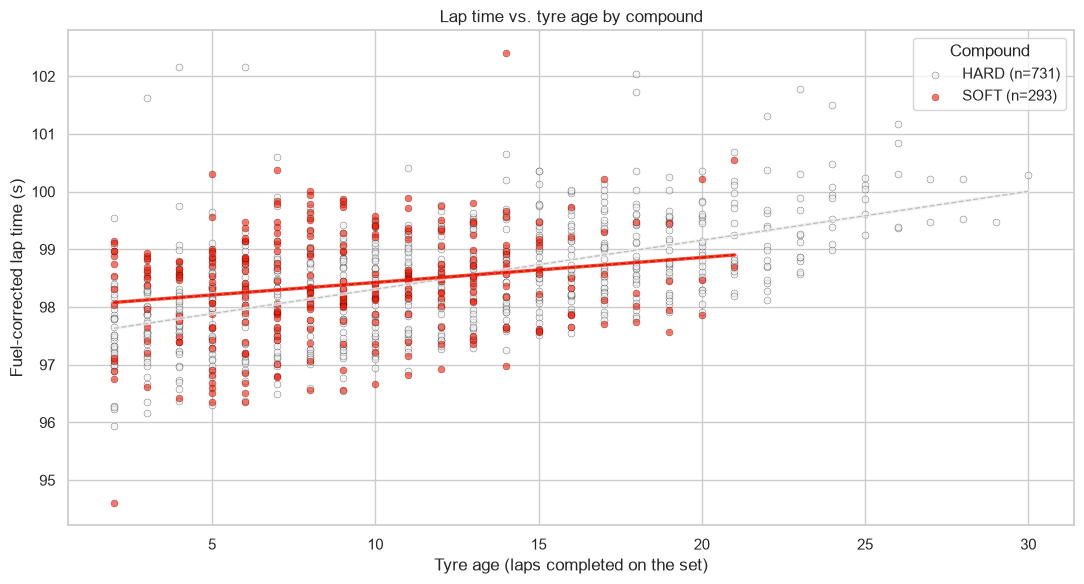

In [7]:
fig_deg = plot_tyre_degradation(df_laps, use_fuel_corrected=True)
plt.show()

In [8]:
stint_summary = compute_driver_stint_summary(df_laps, use_fuel_corrected=True)
stint_summary.head(12)

,driver_id,stint_number,compound,start_lap,end_lap,stint_length_laps,representative_laps,median_pace_sec,degradation_sec_per_lap,r_squared
0,albon,1,SOFT,1,15,15,13,99.073053,0.085307,0.830041
1,albon,2,HARD,16,36,21,19,99.415789,0.074121,0.775828
2,albon,3,HARD,37,56,20,19,98.447053,0.117833,0.671660
3,alonso,1,SOFT,1,15,15,13,99.121947,0.083088,0.297613
4,alonso,2,HARD,16,41,26,24,98.556816,0.074344,0.699179
5,alonso,3,HARD,42,57,16,15,97.546211,0.076096,0.504334
6,bottas,1,SOFT,1,12,12,10,99.402789,0.114922,0.359462
7,bottas,2,HARD,13,30,18,16,99.194132,0.151837,0.875063
8,bottas,3,HARD,31,56,26,25,99.238684,0.070020,0.381813
9,gasly,1,SOFT,1,12,12,10,99.272237,0.078456,0.396832


## 5. Module C — Pit-Stop Strategy Analysis
We examine pit-lane transit durations, compound sequences, and observed undercut sequences.

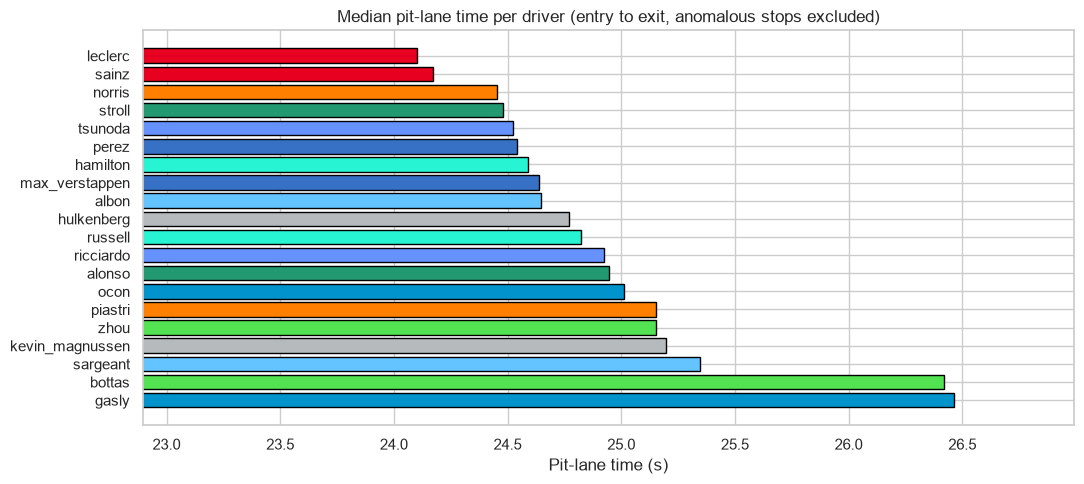

,driver_id,total_stops,anomalous_stops,pit_laps,fastest_pit_lane_sec,median_pit_lane_sec,total_pit_lane_sec,driver_name,constructor_name,position
0,leclerc,2,0,"[11, 34]",24.069,24.1025,48.205,Charles Leclerc,Ferrari,4
1,sainz,2,0,"[14, 35]",23.866,24.1700,48.340,Carlos Sainz,Ferrari,3
2,norris,2,0,"[13, 33]",24.205,24.4550,48.910,Lando Norris,McLaren,6
3,stroll,2,0,"[9, 27]",24.418,24.4815,48.963,Lance Stroll,Aston Martin,10
4,tsunoda,2,0,"[14, 34]",24.324,24.5240,49.048,Yuki Tsunoda,RB F1 Team,14
5,perez,2,0,"[12, 36]",24.516,24.5395,49.079,Sergio Pérez,Red Bull,2
6,hamilton,2,0,"[12, 33]",24.094,24.5905,49.181,Lewis Hamilton,Mercedes,7
7,max_verstappen,2,0,"[17, 37]",24.209,24.6365,49.273,Max Verstappen,Red Bull,1
8,albon,2,0,"[15, 36]",24.610,24.6455,49.291,Alexander Albon,Williams,15
9,hulkenberg,3,0,"[1, 20, 41]",24.387,24.7680,85.759,Nico Hülkenberg,Haas F1 Team,16


In [9]:
pit_summary = compute_pit_stop_summary(df_pitstops, df_results)
fig_pit = plot_pit_stop_times(pit_summary)
plt.show()
pit_summary.head(10)

In [10]:
strat_table = strategy_vs_result(df_pitstops, df_results, df_laps)
strat_table.head(10)

,driver_id,driver_name,constructor_name,grid,position,status,n_stops,compound_sequence
0,max_verstappen,Max Verstappen,Red Bull,1,1,Finished,2,SOFT -> HARD -> SOFT
1,perez,Sergio Pérez,Red Bull,5,2,Finished,2,SOFT -> HARD -> SOFT
2,sainz,Carlos Sainz,Ferrari,4,3,Finished,2,SOFT -> HARD -> HARD
3,leclerc,Charles Leclerc,Ferrari,2,4,Finished,2,SOFT -> HARD -> HARD
4,russell,George Russell,Mercedes,3,5,Finished,2,SOFT -> HARD -> HARD
5,norris,Lando Norris,McLaren,7,6,Finished,2,SOFT -> HARD -> HARD
6,hamilton,Lewis Hamilton,Mercedes,9,7,Finished,2,SOFT -> HARD -> HARD
7,piastri,Oscar Piastri,McLaren,8,8,Finished,2,SOFT -> HARD -> HARD
8,alonso,Fernando Alonso,Aston Martin,6,9,Finished,2,SOFT -> HARD -> HARD
9,stroll,Lance Stroll,Aston Martin,12,10,Finished,2,SOFT -> HARD -> HARD


In [11]:
# Observed Stop 2 undercut: Hamilton (pitted lap 33) vs Piastri (pitted lap 34)
undercut_example = analyze_undercut(df_laps, df_pitstops, attacker="hamilton", defender="piastri", stop_number=2)
undercut_example

{'attacker': 'hamilton',
 'defender': 'piastri',
 'stop_number': 2,
 'attacker_pit_lap': 33,
 'defender_pit_lap': 34,
 'gap_before_sec': 2.1809999999991305,
 'gap_after_sec': -3.6620000000007167,
 'net_gain_sec': 5.842999999999847,
 'undercut_worked': True}

## 6. Module D — Race Dynamics & Position Progression

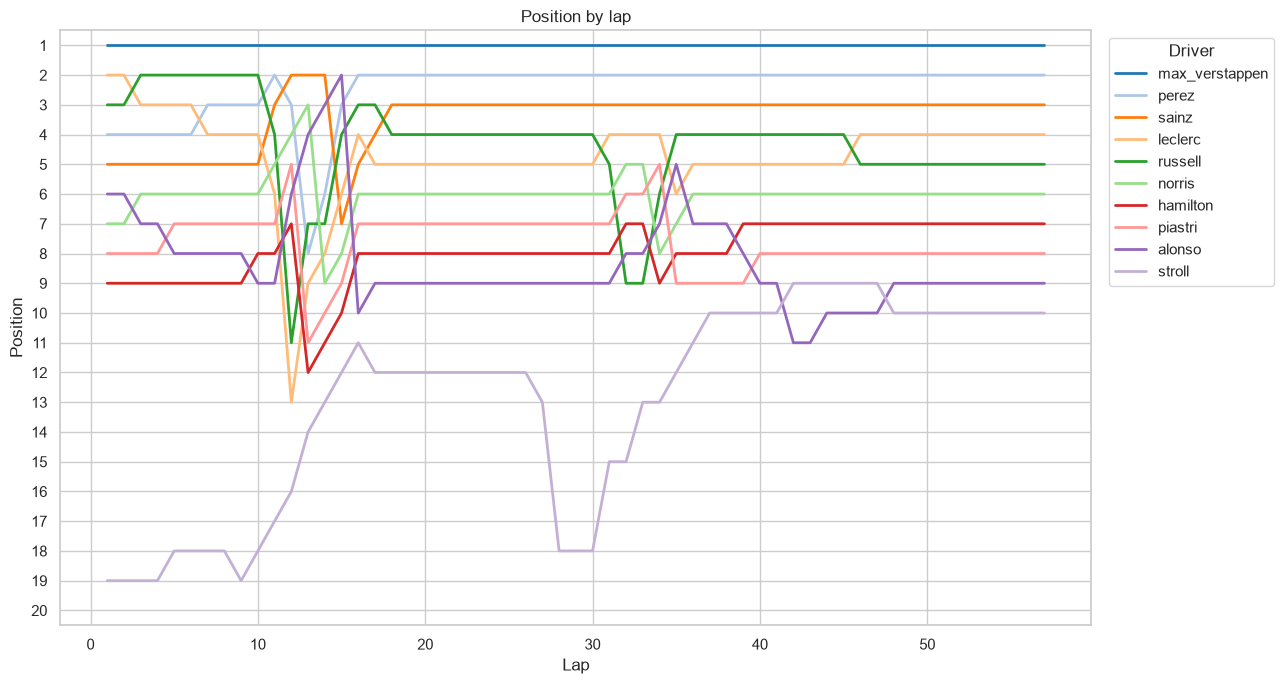

In [12]:
fig_pos = plot_position_progression(df_laps, top_n=10)
plt.show()

In [13]:
net_changes = compute_net_position_changes(df_results)
net_changes.head(10)

,driver_id,driver_name,constructor_name,grid,pit_lane_start,effective_grid,position,finished,status,positions_gained
0,zhou,Guanyu Zhou,Sauber,17,False,17,11,True,Lapped,6
1,perez,Sergio Pérez,Red Bull,5,False,5,2,True,Finished,3
2,kevin_magnussen,Kevin Magnussen,Haas F1 Team,15,False,15,12,True,Lapped,3
3,hamilton,Lewis Hamilton,Mercedes,9,False,9,7,True,Finished,2
4,ocon,Esteban Ocon,Alpine F1 Team,19,False,19,17,True,Lapped,2
5,gasly,Pierre Gasly,Alpine F1 Team,20,False,20,18,True,Lapped,2
6,stroll,Lance Stroll,Aston Martin,12,False,12,10,True,Finished,2
7,sainz,Carlos Sainz,Ferrari,4,False,4,3,True,Finished,1
8,norris,Lando Norris,McLaren,7,False,7,6,True,Finished,1
9,ricciardo,Daniel Ricciardo,RB F1 Team,14,False,14,13,True,Lapped,1


## 7. Module E — Constructor Pace & Multi-Round Championship Trend

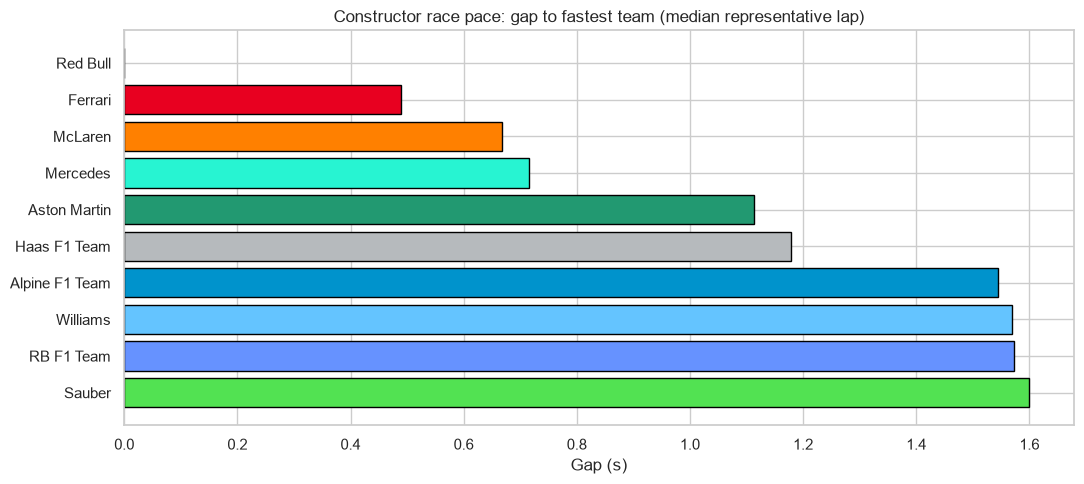

,constructor_id,constructor_name,representative_laps,median_lap_sec,mean_lap_sec,std_lap_sec,iqr_lap_sec,gap_to_fastest_sec
0,red_bull,Red Bull,104,97.398763,97.361295,0.692515,1.020053,0.000000
1,ferrari,Ferrari,104,97.887921,97.757960,0.619251,0.988763,0.489158
2,mclaren,McLaren,104,98.066079,98.024888,0.614660,0.917026,0.667316
3,mercedes,Mercedes,104,98.114921,98.013920,0.626319,0.964526,0.716158
4,aston_martin,Aston Martin,104,98.511421,98.556426,0.767330,1.127711,1.112658
5,haas,Haas F1 Team,101,98.578105,98.661077,0.803311,1.017000,1.179342
6,alpine,Alpine F1 Team,100,98.942711,99.053763,0.797551,1.131579,1.543947
7,williams,Williams,99,98.967526,99.022836,0.960315,1.012053,1.568763
8,rb,RB F1 Team,102,98.971684,98.949338,0.768471,1.053947,1.572921
9,sauber,Sauber,102,98.997711,99.073176,0.791027,0.935724,1.598947


In [14]:
team_pace = compute_constructor_pace_ranking(df_laps, df_results, use_fuel_corrected=True)
fig_team = plot_constructor_pace(team_pace)
plt.show()
team_pace

In [15]:
team_points = compute_constructor_points_summary(df_results)
team_points

,constructor_id,constructor_name,total_points,best_finish,drivers_in_top10,double_top10_finish
0,red_bull,Red Bull,44.0,1,2,True
1,ferrari,Ferrari,27.0,3,2,True
2,mercedes,Mercedes,16.0,5,2,True
3,mclaren,McLaren,12.0,6,2,True
4,aston_martin,Aston Martin,3.0,9,2,True
5,sauber,Sauber,0.0,11,0,False
6,haas,Haas F1 Team,0.0,12,0,False
7,rb,RB F1 Team,0.0,13,0,False
8,williams,Williams,0.0,15,0,False
9,alpine,Alpine F1 Team,0.0,17,0,False


In [16]:
# Multi-round constructor points progression across Rounds 1-3 (Bahrain, Saudi Arabia, Australia)
season_pts = compute_season_constructor_points(F1DataLoader(), year=2024, rounds=[1, 2, 3])
season_pts.pivot(index="round", columns="constructor_name", values="cumulative_points")

constructor_name,Alpine F1 Team,Aston Martin,Ferrari,Haas F1 Team,McLaren,Mercedes,RB F1 Team,Red Bull,Sauber,Williams
round,,,,,,,,,,
1,0.0,3.0,27.0,0.0,12.0,16.0,0.0,44.0,0.0,0.0
2,0.0,13.0,49.0,1.0,28.0,26.0,0.0,87.0,0.0,0.0
3,0.0,25.0,93.0,4.0,55.0,26.0,6.0,97.0,0.0,0.0
